# Lab Sheet 01

Harsh Saini | Roll 253028036

MCA III Semester, Session 2026-2027

Run all cells in order from this folder. Outputs below are captured from execution, not typed examples. See README for dataset sources.

## Common setup
Run once before Program 1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this file or notebook from the practicals folder.
DATA = Path("datasets")
OUT = Path("outputs") / "lab_01"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 78)
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
np.set_printoptions(precision=3, suppress=True)
sns.set_theme(style="whitegrid", font_scale=0.9)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160)
    plt.show()


## Program 01: Install Python and verify the installed version using Python commands.

**Procedure:** Install Python, open a terminal, and check the version using python --version.

In [2]:
import platform
print("Python:", platform.python_version())
print("Executable:", Path(sys.executable).name)
print("Python >= 3.11:", sys.version_info >= (3, 11))


Python: 3.12.14
Executable: python
Python >= 3.11: True


**Observation:** The interpreter version meets the requirement. Install from python.org if Python is missing.

## Program 02: Install Jupyter Notebook and launch the notebook interface.

**Procedure:** Install with python -m pip install notebook. Check its version and launch python -m notebook.

In [3]:
import subprocess
result = subprocess.run(
    [sys.executable, "-m", "notebook", "--version"],
    capture_output=True, text=True, check=True)
print("Jupyter Notebook version:", result.stdout.strip())
print("Launch command: python -m notebook")


Jupyter Notebook version: 7.6.3
Launch command: python -m notebook


**Observation:** The Notebook package is installed. Use the launch command to open the notebook interface locally.

## Program 03: Install NumPy using pip and verify its installation.

**Procedure:** Install with python -m pip install numpy, import the library, and create an array.

In [4]:
import numpy
print("NumPy version:", numpy.__version__)
print("Array:", numpy.array([10, 20, 30]))


NumPy version: 2.3.5
Array: [10 20 30]


**Observation:** NumPy was imported and an array was created.

## Program 04: Install Pandas using pip and verify its installation.

**Procedure:** Install with python -m pip install pandas, import it, and create a DataFrame.

In [5]:
import pandas
print("Pandas version:", pandas.__version__)
print(pandas.DataFrame({"name": ["Aman", "Riya"],
                        "marks": [78, 88]}))


Pandas version: 2.2.3
   name  marks
0  Aman     78
1  Riya     88


**Observation:** Pandas displays labelled rows and columns.

## Program 05: Install Matplotlib and create a simple line plot.

**Procedure:** Install Matplotlib, give x and y values, then plot and label the axes.

Matplotlib version: 3.10.8


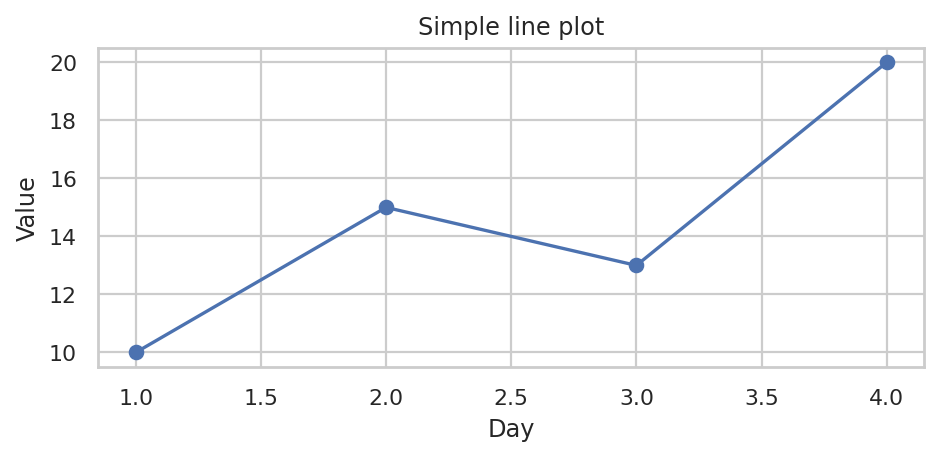

In [6]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)
plt.figure(figsize=(6, 3))
plt.plot([1, 2, 3, 4], [10, 15, 13, 20], marker="o")
plt.xlabel("Day")
plt.ylabel("Value")
plt.title("Simple line plot")
save_plot("05_line_plot")


**Observation:** The line connects the values in their original order.

## Program 06: Install Seaborn and generate a basic statistical plot.

**Procedure:** Install Seaborn, supply categories and values, and draw a bar plot.

Seaborn version: 0.13.2


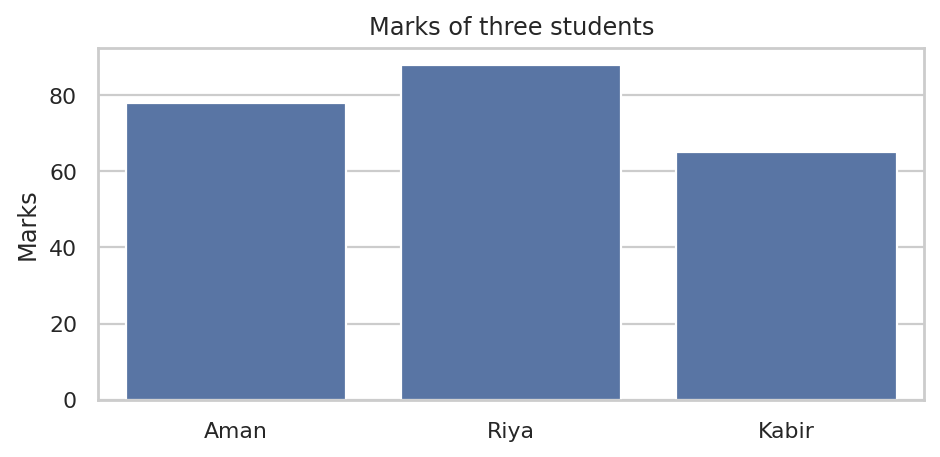

In [7]:
print("Seaborn version:", sns.__version__)
plt.figure(figsize=(6, 3))
sns.barplot(x=["Aman", "Riya", "Kabir"], y=[78, 88, 65])
plt.ylabel("Marks")
plt.title("Marks of three students")
save_plot("06_bar_plot")


**Observation:** The tallest bar represents the highest mark.

## Program 07: Install Scikit-learn and verify its version.

**Procedure:** Install with python -m pip install scikit-learn and verify the version.

In [8]:
import sklearn
from sklearn.datasets import load_iris
print("Scikit-learn version:", sklearn.__version__)
print("Iris shape:", load_iris().data.shape)


Scikit-learn version: 1.8.0
Iris shape: (150, 4)


**Observation:** Scikit-learn was imported and its built-in dataset loaded.

## Program 08: Create and execute your first Python program in Jupyter Notebook.

**Procedure:** Create a notebook, enter the code in a cell, and press Shift+Enter.

In [9]:
# Paste these statements in a Jupyter code cell.
print("Hello, Python!")
a = 12
b = 8
print("Sum:", a + b)


Hello, Python!
Sum: 20


**Observation:** The first code cell prints a message and adds two numbers.

## Program 09: Create and execute a Python script using Visual Studio Code or PyCharm.

**Procedure:** Create a .py file, enter the code, select the Python interpreter, and run it.

In [10]:
# Save as first_program.py and run in VS Code or PyCharm.
length = 8
width = 5
area = length * width
print("Length:", length)
print("Width:", width)
print("Area:", area)


Length: 8
Width: 5
Area: 40


**Observation:** The script computes an area of 40 square units.

## Program 10: Create a virtual environment and install required Python libraries inside it.

**Procedure:** Create a virtual environment, activate it, install requirements, and verify imports.

In [11]:
import tempfile
import venv
import subprocess

# Reuse installed packages for this lightweight demonstration.
with tempfile.TemporaryDirectory() as temp:
    folder = Path(temp) / "demo_env"
    venv.EnvBuilder(system_site_packages=True).create(folder)
    executable = folder / (
        "Scripts/python.exe" if sys.platform == "win32"
        else "bin/python")
    result = subprocess.run(
        [str(executable), "-c",
         "import numpy, pandas; print('Libraries verified')"],
        capture_output=True, text=True, check=True)
    print("Virtual environment created:", folder.exists())
    print(result.stdout.strip())
print("For a fresh local environment:")
print("python -m venv .venv")
print(".venv\\Scripts\\activate   (Windows)")
print("python -m pip install -r requirements.txt")


Virtual environment created: True
Libraries verified
For a fresh local environment:
python -m venv .venv
.venv\Scripts\activate   (Windows)
python -m pip install -r requirements.txt


**Observation:** The demonstration checks a separate interpreter with inherited libraries. The commands below it install packages in a fresh local environment.

## Program 11: Load a CSV dataset using the Pandas library.

**Procedure:** Read the student CSV with read_csv and check that loading succeeded.

In [12]:
try:
    students = pd.read_csv(DATA / "students.csv")
    print("Dataset loaded:", students.shape)
    print(students.head(3))
except (FileNotFoundError, pd.errors.ParserError) as error:
    raise RuntimeError("Check datasets/students.csv") from error


Dataset loaded: (12, 4)
    name    age course  marks
0   Aman 21.000    MCA 78.000
1   Riya 22.000    MCA 88.000
2  Kabir 21.000    BCA 65.000


**Observation:** The CSV contains 12 records, including missing values and one duplicate.

## Program 12: Display the first five records of a dataset using head().

**Procedure:** Call head() on the loaded DataFrame.

In [13]:
print(students.head())


    name    age course  marks
0   Aman 21.000    MCA 78.000
1   Riya 22.000    MCA 88.000
2  Kabir 21.000    BCA 65.000
3   Neha 23.000    MCA    NaN
4  Arjun 22.000    BCA 72.000


**Observation:** head() displays the first five rows.

## Program 13: Display the last five records of a dataset using tail().

**Procedure:** Call tail() on the loaded DataFrame.

In [14]:
print(students.tail())


     name    age course  marks
7    Isha 22.000    BCA 84.000
8     Raj 23.000    MCA 75.000
9   Meera 21.000    MCA 86.000
10   Yash    NaN    BCA 62.000
11   Aman 21.000    MCA 78.000


**Observation:** tail() displays the last five rows.

## Program 14: Find the total number of rows and columns in a dataset.

**Procedure:** Read the two values returned by shape.

In [15]:
rows, columns = students.shape
print("Rows:", rows)
print("Columns:", columns)


Rows: 12
Columns: 4


**Observation:** shape returns the row count followed by the column count.

## Program 15: Display the names of all columns in the dataset.

**Procedure:** Convert the column index to a list.

In [16]:
print("Columns:", students.columns.tolist())


Columns: ['name', 'age', 'course', 'marks']


**Observation:** Column names can be accessed through columns.

## Program 16: Check the data types of all columns.

**Procedure:** Display dtypes for each column.

In [17]:
print(students.dtypes)


name       object
age       float64
course     object
marks     float64
dtype: object


**Observation:** Text columns have object dtype; missing numeric values make these columns floating point.

## Program 17: Generate descriptive statistics of numerical features.

**Procedure:** Generate count, mean, standard deviation, and quartiles with describe().

In [18]:
print(students.describe())


         age  marks
count 11.000 11.000
mean  21.909 77.091
std    1.044  9.544
min   21.000 62.000
25%   21.000 70.500
50%   22.000 78.000
75%   22.500 85.000
max   24.000 91.000


**Observation:** describe() ignores missing numerical entries when computing statistics.

## Program 18: Display complete information about the dataset using info().

**Procedure:** Call info() to inspect the dataset structure.

In [19]:
students.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    12 non-null     object 
 1   age     11 non-null     float64
 2   course  12 non-null     object 
 3   marks   11 non-null     float64
dtypes: float64(2), object(2)
memory usage: 516.0+ bytes


**Observation:** info() shows non-null counts and data types.

## Program 19: Identify missing values in the dataset.

**Procedure:** Create a Boolean missing-value mask using isna().

In [20]:
print(students.isna())


     name    age  course  marks
0   False  False   False  False
1   False  False   False  False
2   False  False   False  False
3   False  False   False   True
4   False  False   False  False
5   False  False   False  False
6   False  False   False  False
7   False  False   False  False
8   False  False   False  False
9   False  False   False  False
10  False   True   False  False
11  False  False   False  False


**Observation:** True marks a missing entry.

## Program 20: Count the total missing values in each column.

**Procedure:** Sum the missing-value mask down each column.

In [21]:
print(students.isna().sum())


name      0
age       1
course    0
marks     1
dtype: int64


**Observation:** The dataset has one missing age and one missing mark.

## Program 21: Display unique values present in a selected column.

**Procedure:** Select course and call unique().

In [22]:
print("Courses:", students["course"].unique())


Courses: ['MCA' 'BCA']


**Observation:** unique() lists each course only once.

## Program 22: Count the frequency of each unique value in a column.

**Procedure:** Count the frequency of course values.

In [23]:
print(students["course"].value_counts())


course
MCA    8
BCA    4
Name: count, dtype: int64


**Observation:** value_counts() gives the number of records in each course.

## Program 23: Rename one or more columns in a dataset.

**Procedure:** Rename name and marks in a copy and display the result.

In [24]:
renamed = students.rename(columns={"name": "student_name",
                                   "marks": "score"})
print(renamed.head(3))


  student_name    age course  score
0         Aman 21.000    MCA 78.000
1         Riya 22.000    MCA 88.000
2        Kabir 21.000    BCA 65.000


**Observation:** The original DataFrame is kept for later experiments.

## Program 24: Select specific rows and columns using loc[].

**Procedure:** Select row labels 0 through 3 and two named columns.

In [25]:
print(students.loc[0:3, ["name", "marks"]])


    name  marks
0   Aman 78.000
1   Riya 88.000
2  Kabir 65.000
3   Neha    NaN


**Observation:** loc uses labels and includes the ending row label.

## Program 25: Select specific rows and columns using iloc[].

**Procedure:** Select the first four rows and columns at positions 0 and 3.

In [26]:
print(students.iloc[0:4, [0, 3]])


    name  marks
0   Aman 78.000
1   Riya 88.000
2  Kabir 65.000
3   Neha    NaN


**Observation:** iloc uses positions and excludes the ending position.

## Program 26: Filter records based on a given condition.

**Procedure:** Build a Boolean condition and use it to filter rows.

In [27]:
print(students.loc[students["marks"] >= 80])


    name    age course  marks
1   Riya 22.000    MCA 88.000
5   Sara 21.000    MCA 91.000
7   Isha 22.000    BCA 84.000
9  Meera 21.000    MCA 86.000


**Observation:** Only records with at least 80 marks are selected.

## Program 27: Sort the dataset using one or more columns.

**Procedure:** Sort by course first and marks second.

In [28]:
print(students.sort_values(["course", "marks"],
                           ascending=[True, False]))


     name    age course  marks
7    Isha 22.000    BCA 84.000
4   Arjun 22.000    BCA 72.000
2   Kabir 21.000    BCA 65.000
10   Yash    NaN    BCA 62.000
5    Sara 21.000    MCA 91.000
1    Riya 22.000    MCA 88.000
9   Meera 21.000    MCA 86.000
0    Aman 21.000    MCA 78.000
11   Aman 21.000    MCA 78.000
8     Raj 23.000    MCA 75.000
6     Dev 24.000    MCA 69.000
3    Neha 23.000    MCA    NaN


**Observation:** Courses are sorted alphabetically and marks descend within each course.

## Program 28: Add a new column to an existing dataset.

**Procedure:** Copy the dataset, calculate a passed column, and preserve unknown marks.

In [29]:
with_column = students.copy()
with_column["passed"] = with_column["marks"].ge(70).where(
    with_column["marks"].notna(), other=pd.NA)
print(with_column.head(6))


    name    age course  marks passed
0   Aman 21.000    MCA 78.000   True
1   Riya 22.000    MCA 88.000   True
2  Kabir 21.000    BCA 65.000  False
3   Neha 23.000    MCA    NaN   <NA>
4  Arjun 22.000    BCA 72.000   True
5   Sara 21.000    MCA 91.000   True


**Observation:** A missing mark stays unknown instead of being labelled as a fail.

## Program 29: Delete an existing column from the dataset.

**Procedure:** Remove passed from the copied dataset.

In [30]:
without_column = with_column.drop(columns="passed")
print("Remaining columns:", without_column.columns.tolist())


Remaining columns: ['name', 'age', 'course', 'marks']


**Observation:** drop() removes the added column.

## Program 30: Remove duplicate records from a dataset.

**Procedure:** Call drop_duplicates() and compare row counts.

In [31]:
deduplicated = students.drop_duplicates()
print("Before:", len(students))
print("After:", len(deduplicated))
print("Duplicates removed:", len(students) - len(deduplicated))


Before: 12
After: 11
Duplicates removed: 1


**Observation:** The repeated Aman record is removed.

## Program 31: Save the modified dataset as a new CSV file.

**Procedure:** Save the modified dataset and reload it to verify the shape.

In [32]:
deduplicated.to_csv(OUT / "students_modified.csv", index=False)
reloaded = pd.read_csv(OUT / "students_modified.csv")
print("Saved file: students_modified.csv")
print("Reloaded shape:", reloaded.shape)


Saved file: students_modified.csv
Reloaded shape: (11, 4)


**Observation:** index=False avoids an unnecessary index column in the CSV.

## Program 32: Load a dataset directly from the Scikit-learn library.

**Procedure:** Load the built-in Iris dataset as a DataFrame.

In [33]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
print("Feature shape:", iris.data.shape)
print("Target names:", iris.target_names)
print(iris.data.head(3))


Feature shape: (150, 4)
Target names: ['setosa' 'versicolor' 'virginica']
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0              5.100             3.500              1.400             0.200
1              4.900             3.000              1.400             0.200
2              4.700             3.200              1.300             0.200


**Observation:** Iris has 150 samples, four numerical features, and three target classes.

## Program 33: Create a histogram for a numerical feature using Matplotlib.

**Procedure:** Drop missing marks and draw a histogram.

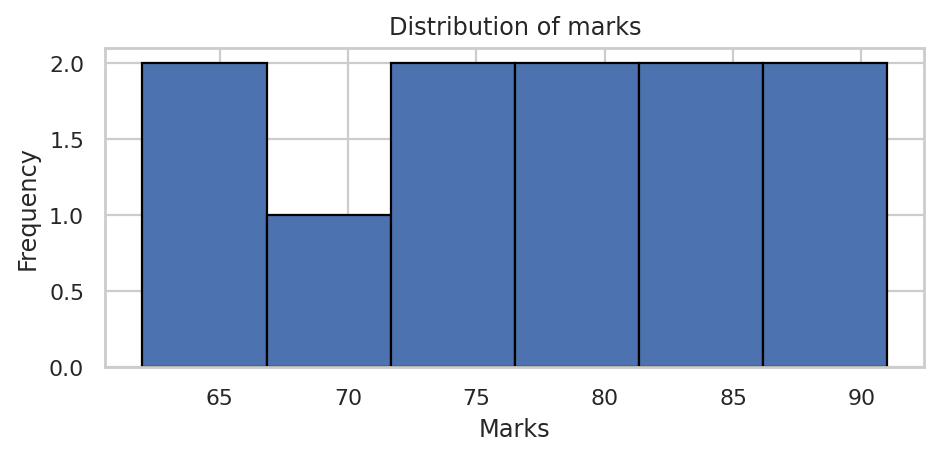

In [34]:
plt.figure(figsize=(6, 3))
plt.hist(students["marks"].dropna(), bins=6, edgecolor="black")
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.title("Distribution of marks")
save_plot("33_histogram")


**Observation:** Missing marks are excluded from the histogram.

## Program 34: Create a scatter plot to visualize the relationship between two variables.

**Procedure:** Plot age on the horizontal axis and marks on the vertical axis.

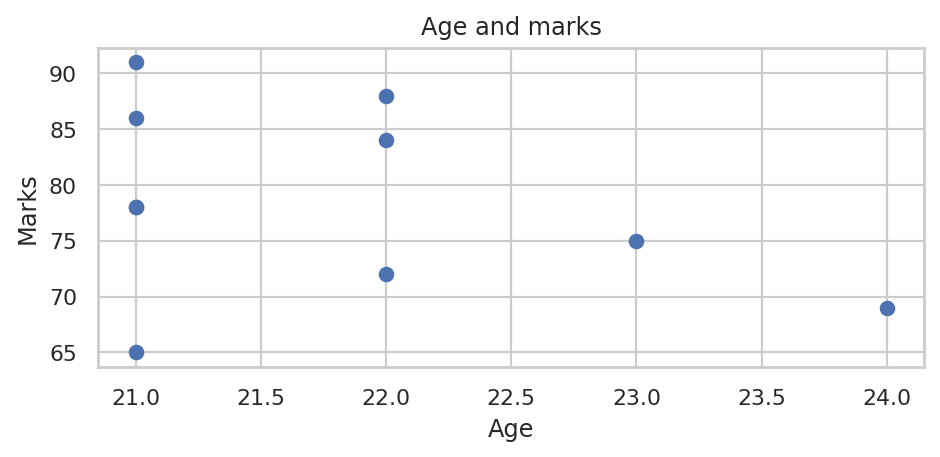

In [35]:
plt.figure(figsize=(6, 3))
plt.scatter(students["age"], students["marks"])
plt.xlabel("Age")
plt.ylabel("Marks")
plt.title("Age and marks")
save_plot("34_scatter")


**Observation:** The scatter plot shows individual observations; it does not establish causation.

## Program 35: Generate a correlation matrix and visualize it using a heatmap.

**Procedure:** Calculate numerical correlations and display a heatmap.

         age  marks
age    1.000 -0.349
marks -0.349  1.000


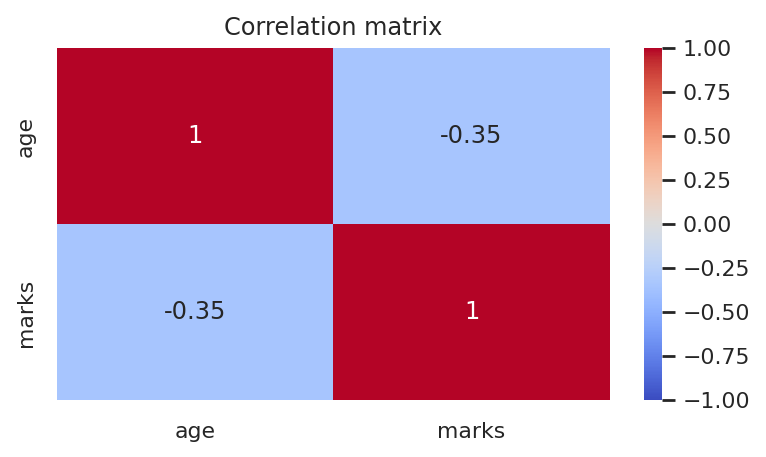

In [36]:
correlation = students[["age", "marks"]].corr()
print(correlation)
plt.figure(figsize=(5, 3))
sns.heatmap(correlation, annot=True, vmin=-1, vmax=1,
            cmap="coolwarm")
plt.title("Correlation matrix")
save_plot("35_correlation")


**Observation:** The matrix describes linear association using available pairs of values.